# 26SP-5

Entropy-enabled steady-front profile test notebook.


## Conservative Entropy-Profile Trial

This notebook tests `solve_steady_front_entropy(...)` on a conservative point:
- `T = 10` MeV
- `n_{B,N} = 2 n_0`
- `B^{1/4} = 180` MeV
- `a_{Q^\star} = 0.01`

The entropy-enabled solve is seeded with `j_B` from the current production BVP solver.


In [1]:
# ENTROPY_PROFILE_TRIAL
# Conservative single-trial run for the entropy-enabled compact BVP solver.

import numpy as np

import RMFsolver.constants as const
from RMFsolver.phase_velocity import solve_steady_front_1d_aQstar_rescale_bvp, solve_steady_front_entropy

# -------------------------
# Conservative entropy-solver trial inputs
# -------------------------
T_entropy_trial = 50.0
n0 = 0.16 * const.MeV_fm**3
nB_N_entropy_trial = 2.0 * n0
B14_entropy_trial = 180.0
ms_entropy_trial = 0.0

aQstar_entropy_trial = 0.29
tail_eps_entropy_trial = 1.0e-6

# Seed solve: current production BVP path.
n_mesh_seed_entropy_trial = 80
tol_seed_entropy_trial = 1.0e-3
max_nodes_seed_entropy_trial = 500
jB_guess_seed_entropy_trial =  max(0.02, 1.2 * aQstar_entropy_trial)

# Entropy-enabled solve.
n_mesh_entropy_trial = 60
tol_entropy_trial = 5.0e-3
max_nodes_entropy_trial = 800
jB_bounds_entropy_trial = (1e-5, 5.0)
verb_entropy_trial = False

# -------------------------
# Step 1: seed with the current production solver
# -------------------------
res_entropy_seed = solve_steady_front_1d_aQstar_rescale_bvp(
    T=T_entropy_trial,
    nB_N=nB_N_entropy_trial,
    B_one_forth=B14_entropy_trial,
    aQstar=aQstar_entropy_trial,
    ms=ms_entropy_trial,
    tail_eps=tail_eps_entropy_trial,
    n_mesh=n_mesh_seed_entropy_trial,
    tol_bvp=tol_seed_entropy_trial,
    max_nodes=max_nodes_seed_entropy_trial,
    jB_guess=jB_guess_seed_entropy_trial,
    jB_bounds=jB_bounds_entropy_trial,
    return_profile=False,
    verb=verb_entropy_trial,
)

if not np.isfinite(res_entropy_seed.get('jB', np.nan)):
    raise RuntimeError('Seed BVP solve did not return a finite jB.')

jB_guess_entropy_trial = float(res_entropy_seed['jB'])

# -------------------------
# Step 2: run the entropy-enabled solver
# -------------------------
res_entropy_trial = solve_steady_front_entropy(
    T=T_entropy_trial,
    nB_N=nB_N_entropy_trial,
    B_one_forth=B14_entropy_trial,
    aQstar=aQstar_entropy_trial,
    ms=ms_entropy_trial,
    tail_eps=tail_eps_entropy_trial,
    n_mesh=n_mesh_entropy_trial,
    tol_bvp=tol_entropy_trial,
    max_nodes=max_nodes_entropy_trial,
    jB_guess=jB_guess_entropy_trial,
    jB_bounds=jB_bounds_entropy_trial,
    return_profile=True,
    verb=verb_entropy_trial,
)

required_entropy_profile_keys = [
    'x', 'a', 'u', 'muK', 'muB', 'nB', 'w', 'T_profile', 's_profile'
]
missing_entropy_profile_keys = [
    key for key in required_entropy_profile_keys if key not in res_entropy_trial
]
if missing_entropy_profile_keys:
    raise RuntimeError(
        'Entropy trial is missing profile arrays: ' + ', '.join(missing_entropy_profile_keys)
    )

x_end_um_entropy_trial = float(np.max(np.asarray(res_entropy_trial['x'], dtype=float)) * const.MeV_fm / 1.0e9)
T_prof_entropy_trial = np.asarray(res_entropy_trial['T_profile'], dtype=float)
nB_prof_entropy_trial = np.asarray(res_entropy_trial['nB'], dtype=float) / n0

print('Seed solve (current production BVP):')
print(f"  success: {res_entropy_seed.get('success')}")
print(f"  message: {res_entropy_seed.get('message', '')}")
print(f"  jB_seed: {res_entropy_seed.get('jB', np.nan):.8g}")
print(f"  tail_norm: {res_entropy_seed.get('tail_residual_norm', np.nan):.8g}")
print('')
print('Entropy-enabled solve:')
print(f"  success: {res_entropy_trial.get('success')}")
print(f"  message: {res_entropy_trial.get('message', '')}")
print(f"  bvp_status: {res_entropy_trial.get('bvp_status', np.nan)}")
print(f"  bvp_message: {res_entropy_trial.get('bvp_message', '')}")
print(f"  bvp_niter: {res_entropy_trial.get('bvp_niter', np.nan)}")
print(f"  bvp_nodes: {res_entropy_trial.get('bvp_nodes', np.nan)}")
print(f"  jB: {res_entropy_trial.get('jB', np.nan):.8g}")
print(f"  jB/n0: {res_entropy_trial.get('jB', np.nan) / n0 * const.m_per_sec:.8g} m/s")
print(f"  tail_norm: {res_entropy_trial.get('tail_residual_norm', np.nan):.8g}")
print(f"  muK_Qstar: {res_entropy_trial.get('muK_Qstar', np.nan):.8g} MeV")
print(f"  s_Qstar: {res_entropy_trial.get('s_Qstar', np.nan):.8g}")
print(f"  x_end: {res_entropy_trial.get('x_end', np.nan):.8g} MeV^-1 = {x_end_um_entropy_trial:.4g} um")
print(f"  T(x) range: [{np.min(T_prof_entropy_trial):.8g}, {np.max(T_prof_entropy_trial):.8g}] MeV")
print(f"  nB(x)/n0 range: [{np.min(nB_prof_entropy_trial):.8g}, {np.max(nB_prof_entropy_trial):.8g}]")

if not bool(res_entropy_trial.get('success', False)):
    print('')
    print('Note: the entropy-enabled solve returned profile arrays but did not fully converge.')


/Users/janshao/NSM_related/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Seed solve (current production BVP):
  success: True
  message: Compact BVP steady-front solve converged
  jB_seed: 0.30388667
  tail_norm: 4.8467306e-05

Entropy-enabled solve:
  success: True
  message: Entropy-enabled compact BVP steady-front solve converged
  bvp_status: 0
  bvp_message: The algorithm converged to the desired accuracy.
  bvp_niter: 2
  bvp_nodes: 84
  jB: 0.29918508
  jB/n0: 72.959421 m/s
  tail_norm: -1.868371e-05
  muK_Qstar: 73.579312 MeV
  s_Qstar: 17620384
  x_end: 2042642.4 MeV^-1 = 0.4031 um
  T(x) range: [49.999809, 58.452116] MeV
  nB(x)/n0 range: [3.4597308, 3.5377041]


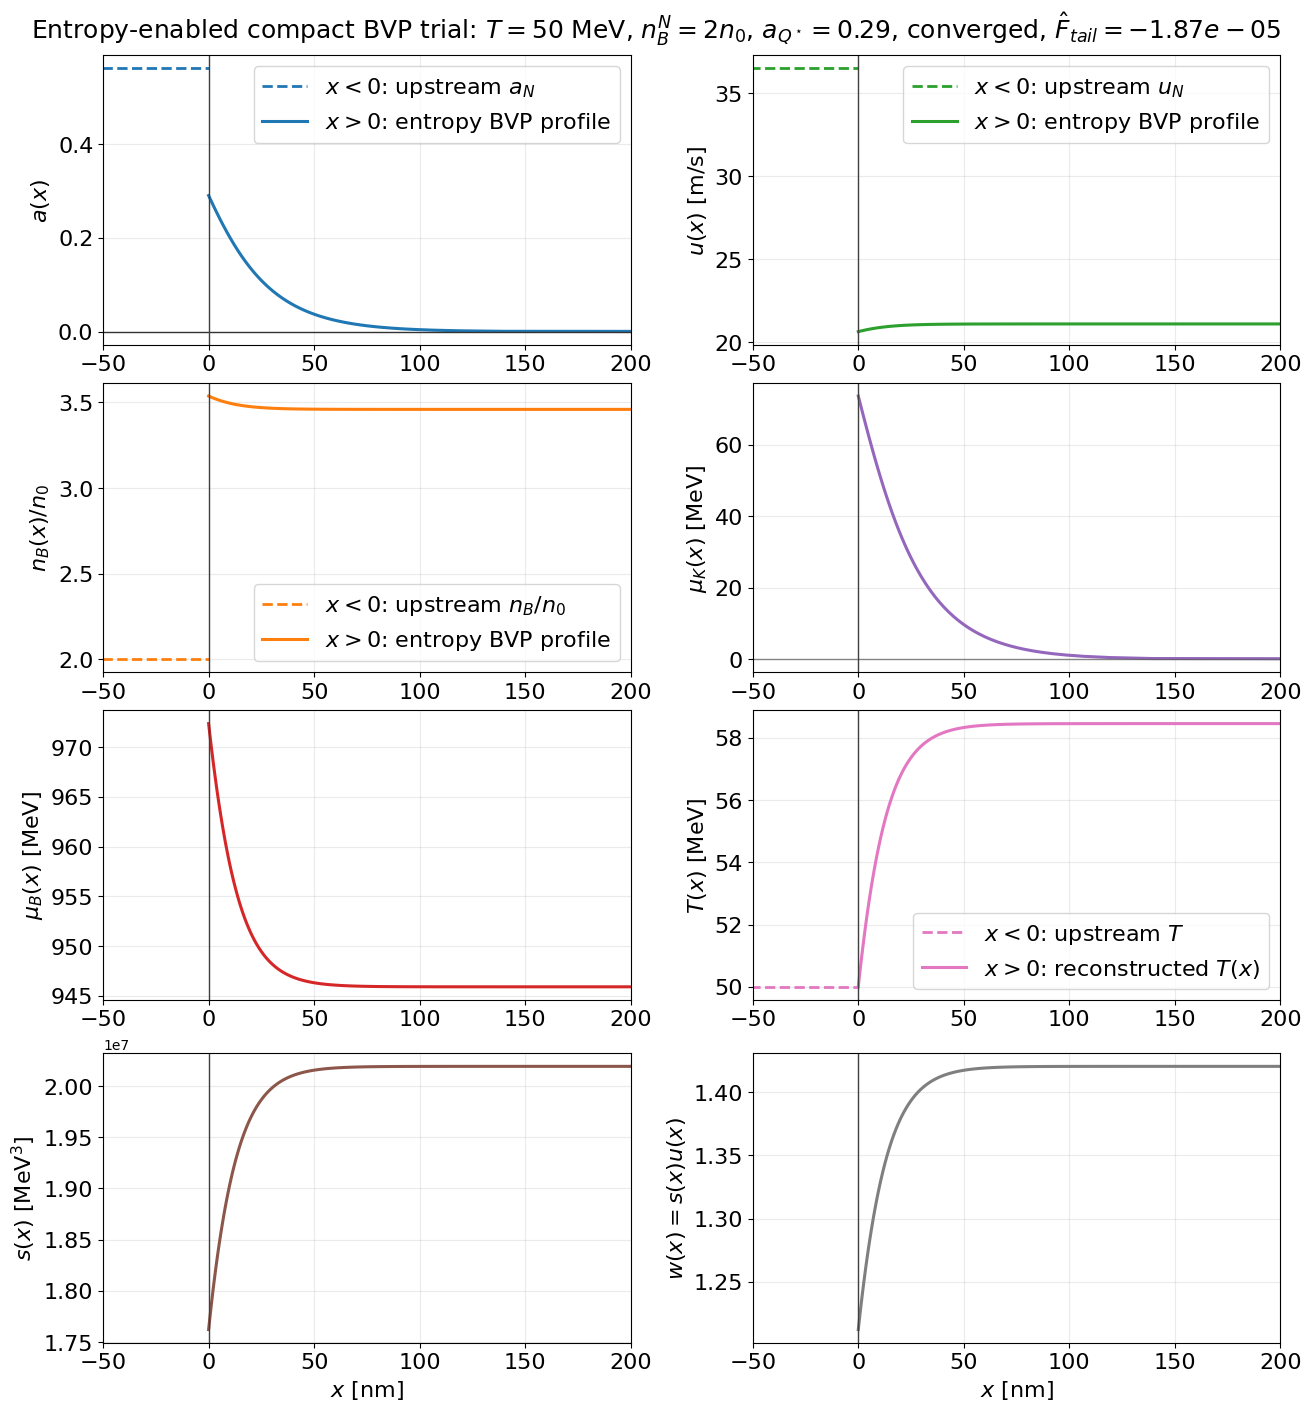

In [2]:
# VISUALIZE_ENTROPY_PROFILE_TRIAL
# Visualize the conservative entropy-enabled single-trial result.

import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const

required_entropy_trial_names = [
    'res_entropy_trial',
    'T_entropy_trial',
    'nB_N_entropy_trial',
    'aQstar_entropy_trial',
    'n0',
]
missing_entropy_trial_names = [name for name in required_entropy_trial_names if name not in globals()]
if missing_entropy_trial_names:
    raise RuntimeError(
        'Run the ENTROPY_PROFILE_TRIAL cell first. Missing names: '
        + ', '.join(missing_entropy_trial_names)
    )

required_entropy_profile_keys = [
    'x', 'a', 'u', 'muK', 'muB', 'nB', 'w', 'T_profile', 's_profile'
]
missing_entropy_profile_keys = [
    key for key in required_entropy_profile_keys if key not in res_entropy_trial
]
if missing_entropy_profile_keys:
    raise RuntimeError(
        'Entropy trial is missing profile arrays: ' + ', '.join(missing_entropy_profile_keys)
    )

x_nm = np.asarray(res_entropy_trial['x'], dtype=float) * const.MeV_fm / 1.0e6
a_prof = np.asarray(res_entropy_trial['a'], dtype=float)
u_ms = np.asarray(res_entropy_trial['u'], dtype=float) * const.m_per_sec
muK_prof = np.asarray(res_entropy_trial['muK'], dtype=float)
muB_prof = np.asarray(res_entropy_trial['muB'], dtype=float)
nB_prof_over_n0 = np.asarray(res_entropy_trial['nB'], dtype=float) / n0
T_prof = np.asarray(res_entropy_trial['T_profile'], dtype=float)
s_prof = np.asarray(res_entropy_trial['s_profile'], dtype=float)
w_prof = np.asarray(res_entropy_trial['w'], dtype=float)

positive_extent_nm = float(np.nanmax(x_nm)) if len(x_nm) else 1.0
positive_extent_nm = max(positive_extent_nm, 1.0e-3)
left_extent_nm = max(0.12 * positive_extent_nm, 500.0)
x_left_nm = np.linspace(-left_extent_nm, 0.0, 120)
a_left = np.full_like(x_left_nm, float(res_entropy_trial.get('a_N', np.nan)), dtype=float)
u_left_ms = np.full_like(x_left_nm, float(res_entropy_trial.get('u_N', np.nan)) * const.m_per_sec, dtype=float)
nB_left_over_n0 = np.full_like(x_left_nm, float(nB_N_entropy_trial / n0), dtype=float)
T_left = np.full_like(x_left_nm, float(T_entropy_trial), dtype=float)

TitleFont = 18
LabelFont = 16
TickFont = 16
LegendFont = 16

fig, axes = plt.subplots(4, 2, figsize=(13.0, 14.0), constrained_layout=True)

axes[0, 0].plot(x_left_nm, a_left, lw=2.0, ls='--', color='C0', label=r'$x<0$: upstream $a_N$')
axes[0, 0].plot(x_nm, a_prof, lw=2.2, color='C0', label=r'$x>0$: entropy BVP profile')
axes[0, 0].axhline(0.0, color='0.20', lw=1.0)
axes[0, 0].set_ylabel(r'$a(x)$', fontsize=LabelFont)
axes[0, 0].legend(fontsize=LegendFont)

axes[0, 1].plot(x_left_nm, u_left_ms, lw=2.0, ls='--', color='C2', label=r'$x<0$: upstream $u_N$')
axes[0, 1].plot(x_nm, u_ms, lw=2.2, color='C2', label=r'$x>0$: entropy BVP profile')
axes[0, 1].set_ylabel(r'$u(x)$ [m/s]', fontsize=LabelFont)
axes[0, 1].legend(fontsize=LegendFont)

axes[1, 0].plot(x_left_nm, nB_left_over_n0, lw=2.0, ls='--', color='C1', label=r'$x<0$: upstream $n_B/n_0$')
axes[1, 0].plot(x_nm, nB_prof_over_n0, lw=2.2, color='C1', label=r'$x>0$: entropy BVP profile')
axes[1, 0].set_ylabel(r'$n_B(x)/n_0$', fontsize=LabelFont)
axes[1, 0].legend(fontsize=LegendFont)

axes[1, 1].plot(x_nm, muK_prof, lw=2.2, color='C4')
axes[1, 1].axhline(0.0, color='0.35', lw=1.0, alpha=0.7)
axes[1, 1].set_ylabel(r'$\mu_K(x)$ [MeV]', fontsize=LabelFont)

axes[2, 0].plot(x_nm, muB_prof, lw=2.2, color='C3')
axes[2, 0].set_ylabel(r'$\mu_B(x)$ [MeV]', fontsize=LabelFont)

axes[2, 1].plot(x_left_nm, T_left, lw=2.0, ls='--', color='C6', label=r'$x<0$: upstream $T$')
axes[2, 1].plot(x_nm, T_prof, lw=2.2, color='C6', label=r'$x>0$: reconstructed $T(x)$')
axes[2, 1].set_ylabel(r'$T(x)$ [MeV]', fontsize=LabelFont)
axes[2, 1].legend(fontsize=LegendFont)

axes[3, 0].plot(x_nm, s_prof, lw=2.2, color='C5')
axes[3, 0].set_ylabel(r'$s(x)$ [MeV$^3$]', fontsize=LabelFont)
axes[3, 0].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)

axes[3, 1].plot(x_nm, w_prof, lw=2.2, color='C7')
axes[3, 1].set_ylabel(r'$w(x)=s(x)u(x)$', fontsize=LabelFont)
axes[3, 1].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)

x_plot_min = -left_extent_nm
x_plot_max = 1.02 * positive_extent_nm
for ax in axes.flat:
    ax.axvline(0.0, color='0.25', lw=1.0)
    ax.set_xlim(-50, 200)
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)

status_text = 'converged' if bool(res_entropy_trial.get('success', False)) else f"status={res_entropy_trial.get('bvp_status', 'NA')}"
fig.suptitle(
    rf'Entropy-enabled compact BVP trial: $T={T_entropy_trial:g}$ MeV, '
    rf'$n_{{B}}^{{N}}=2n_0$, $a_{{Q^\star}}={aQstar_entropy_trial:g}$, '
    rf'{status_text}, $\hat F_{{tail}}={res_entropy_trial.get("tail_residual_norm", np.nan):.2e}$',
    fontsize=TitleFont,
)

fig.savefig(
    'entropy_profile_nm.pdf',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [2]:
# ENTROPY_TQGUESS_PROFILE_TRIAL
# Single-trial run for the entropy-enabled compact BVP solver
# with downstream T_Q treated as a global unknown.

import numpy as np

import RMFsolver.constants as const
from RMFsolver.phase_velocity import solve_steady_front_entropy_TQguess

# -------------------------
# Entropy-TQguess trial inputs
# -------------------------
T_entropy_tq_trial = 0.1
n0 = 0.16 * const.MeV_fm**3
nB_N_entropy_tq_trial = 3.0 * n0
B14_entropy_tq_trial = 180.0
ms_entropy_tq_trial = 0.0

aQstar_entropy_tq_trial = 0.6
tail_eps_entropy_tq_trial = 1.0e-6

# Entropy-TQguess solve.
n_mesh_entropy_tq_trial = 80
tol_entropy_tq_trial = 1.0e-6
max_nodes_entropy_tq_trial = 3000
jB_bounds_entropy_tq_trial = (1.0e-5, 5.0)
TQ_guess_entropy_tq_trial = T_entropy_tq_trial + 50
verb_entropy_tq_trial = False

# -------------------------
# Run the entropy-TQguess solver
# -------------------------
res_entropy_tq_trial = solve_steady_front_entropy_TQguess(
    T=T_entropy_tq_trial,
    nB_N=nB_N_entropy_tq_trial,
    B_one_forth=B14_entropy_tq_trial,
    aQstar=aQstar_entropy_tq_trial,
    ms=ms_entropy_tq_trial,
    tail_eps=tail_eps_entropy_tq_trial,
    n_mesh=n_mesh_entropy_tq_trial,
    tol_bvp=tol_entropy_tq_trial,
    max_nodes=max_nodes_entropy_tq_trial,
    jB_guess=None,
    TQ_guess=TQ_guess_entropy_tq_trial,
    jB_bounds=jB_bounds_entropy_tq_trial,
    return_profile=True,
    verb=verb_entropy_tq_trial,
)

required_entropy_tq_profile_keys = [
    'x', 'a', 'u', 'muK', 'muB', 'nB', 'w', 'T_profile', 's_profile'
]
missing_entropy_tq_profile_keys = [
    key for key in required_entropy_tq_profile_keys if key not in res_entropy_tq_trial
]
if missing_entropy_tq_profile_keys:
    raise RuntimeError(
        'Entropy-TQguess trial is missing profile arrays: '
        + ', '.join(missing_entropy_tq_profile_keys)
    )

x_end_nm_entropy_tq_trial = float(
    np.max(np.asarray(res_entropy_tq_trial['x'], dtype=float)) * const.MeV_fm / 1.0e6
)
T_prof_entropy_tq_trial = np.asarray(res_entropy_tq_trial['T_profile'], dtype=float)
nB_prof_entropy_tq_trial = np.asarray(res_entropy_tq_trial['nB'], dtype=float) / n0

print('Entropy-TQguess solve:')
print(f"  success: {res_entropy_tq_trial.get('success')}")
print(f"  message: {res_entropy_tq_trial.get('message', '')}")
print(f"  bvp_status: {res_entropy_tq_trial.get('bvp_status', np.nan)}")
print(f"  bvp_message: {res_entropy_tq_trial.get('bvp_message', '')}")
print(f"  bvp_niter: {res_entropy_tq_trial.get('bvp_niter', np.nan)}")
print(f"  bvp_nodes: {res_entropy_tq_trial.get('bvp_nodes', np.nan)}")
print(f"  jB: {res_entropy_tq_trial.get('jB', np.nan):.8g}")
print(f"  T_Q: {res_entropy_tq_trial.get('T_Q', np.nan):.8g} MeV")
print(f"  w_Q: {res_entropy_tq_trial.get('w_Q', np.nan):.8g}")
print(f"  tail_norm: {res_entropy_tq_trial.get('tail_residual_norm', np.nan):.8g}")
print(f"  entropy_tail_norm: {res_entropy_tq_trial.get('entropy_tail_residual_norm', np.nan):.8g}")
print(f"  muB_Q: {res_entropy_tq_trial.get('muB_Q', np.nan):.8g} MeV")
print(f"  muK_Qstar: {res_entropy_tq_trial.get('muK_Qstar', np.nan):.8g} MeV")
print(f"  x_end: {x_end_nm_entropy_tq_trial:.6g} nm")
print(
    f"  T range: [{np.min(T_prof_entropy_tq_trial):.6g}, {np.max(T_prof_entropy_tq_trial):.6g}] MeV"
)
print(
    f"  nB/n0 range: [{np.min(nB_prof_entropy_tq_trial):.6g}, {np.max(nB_prof_entropy_tq_trial):.6g}]"
)


Entropy-TQguess solve:
  success: True
  message: Entropy-TQguess compact BVP steady-front solve converged
  bvp_status: 0
  bvp_message: The algorithm converged to the desired accuracy.
  bvp_niter: 12
  bvp_nodes: 726
  jB: 1.5439293
  T_Q: 47.138046 MeV
  w_Q: 5.5794903
  tail_norm: -4.741827e-14
  entropy_tail_norm: 6.8131737e-14
  muB_Q: 1067.3927 MeV
  muK_Qstar: 152.82887 MeV
  x_end: 621.366 nm
  T range: [0.1, 47.138] MeV
  nB/n0 range: [4.35527, 4.50555]


In [4]:
from scipy.optimize import fsolve 
from RMFsolver.phase_velocity import PNM, PQM, nB_NM
T = 0
muB_crit = fsolve(lambda x: PNM(x, T) - PQM(x, 0, B_one_forth=180, T=T, ms=0), 1010)[0]
3*n0 / nB_NM(muB_crit, 0)

1.2875299520228858

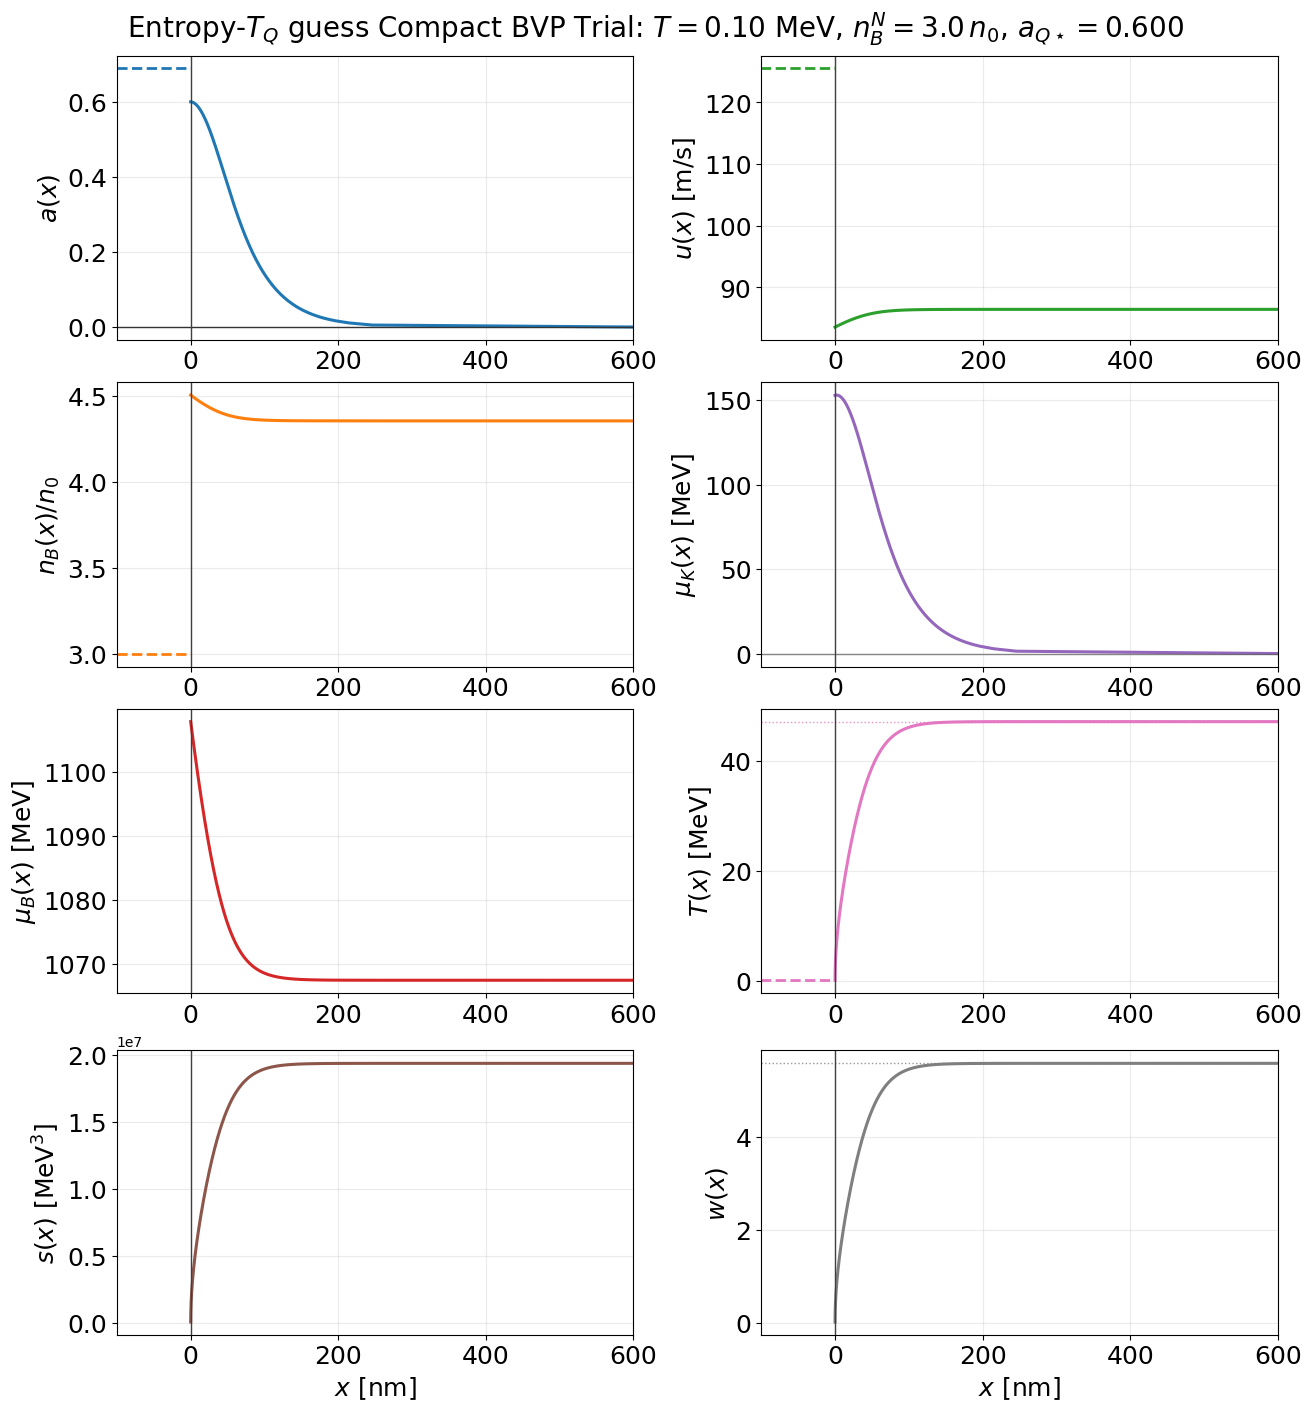

In [4]:
# VISUALIZE_ENTROPY_TQGUESS_PROFILE_TRIAL
# Visualize the entropy-TQguess single-trial result.

import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const

required_entropy_tq_trial_names = [
    'res_entropy_tq_trial',
    'T_entropy_tq_trial',
    'nB_N_entropy_tq_trial',
    'aQstar_entropy_tq_trial',
    'n0',
]
missing_entropy_tq_trial_names = [
    name for name in required_entropy_tq_trial_names if name not in globals()
]
if missing_entropy_tq_trial_names:
    raise RuntimeError(
        'Run the ENTROPY_TQGUESS_PROFILE_TRIAL cell first. Missing names: '
        + ', '.join(missing_entropy_tq_trial_names)
    )

required_entropy_tq_profile_keys = [
    'x', 'a', 'u', 'muK', 'muB', 'nB', 'w', 'T_profile', 's_profile'
]
missing_entropy_tq_profile_keys = [
    key for key in required_entropy_tq_profile_keys if key not in res_entropy_tq_trial
]
if missing_entropy_tq_profile_keys:
    raise RuntimeError(
        'Entropy-TQguess trial is missing profile arrays: '
        + ', '.join(missing_entropy_tq_profile_keys)
    )

x_nm = np.asarray(res_entropy_tq_trial['x'], dtype=float) * const.MeV_fm / 1.0e6
a_prof = np.asarray(res_entropy_tq_trial['a'], dtype=float)
u_ms = np.asarray(res_entropy_tq_trial['u'], dtype=float) * const.m_per_sec
muK_prof = np.asarray(res_entropy_tq_trial['muK'], dtype=float)
muB_prof = np.asarray(res_entropy_tq_trial['muB'], dtype=float)
nB_prof_over_n0 = np.asarray(res_entropy_tq_trial['nB'], dtype=float) / n0
T_prof = np.asarray(res_entropy_tq_trial['T_profile'], dtype=float)
s_prof = np.asarray(res_entropy_tq_trial['s_profile'], dtype=float)
w_prof = np.asarray(res_entropy_tq_trial['w'], dtype=float)

positive_extent_nm = float(np.nanmax(x_nm)) if len(x_nm) else 1.0
positive_extent_nm = max(positive_extent_nm, 1.0e-3)
left_extent_nm = max(0.12 * positive_extent_nm, 500.0)
x_left_nm = np.linspace(-left_extent_nm, 0.0, 120)
a_left = np.full_like(x_left_nm, float(res_entropy_tq_trial.get('a_N', np.nan)), dtype=float)
u_left_ms = np.full_like(
    x_left_nm,
    float(res_entropy_tq_trial.get('u_N', np.nan)) * const.m_per_sec,
    dtype=float,
)
nB_left_over_n0 = np.full_like(x_left_nm, float(nB_N_entropy_tq_trial / n0), dtype=float)
T_left = np.full_like(x_left_nm, float(T_entropy_tq_trial), dtype=float)
x_right_limit_nm = max(1.02 * positive_extent_nm, 500.0)
x_left_limit_nm = -min(left_extent_nm, 0.2 * x_right_limit_nm)

TitleFont = 20
LabelFont = 18
TickFont = 18
LegendFont = 18

fig, axes = plt.subplots(4, 2, figsize=(13.0, 14.0), constrained_layout=True)

axes[0, 0].plot(x_left_nm, a_left, lw=2.0, ls='--', color='C0', label=r'$x<0$: upstream $a_N$')
axes[0, 0].plot(x_nm, a_prof, lw=2.2, color='C0', label=r'$x>0$: entropy-TQguess profile')
axes[0, 0].axhline(0.0, color='0.20', lw=1.0)
axes[0, 0].set_ylabel(r'$a(x)$', fontsize=LabelFont)
#axes[0, 0].legend(fontsize=LegendFont)

axes[0, 1].plot(x_left_nm, u_left_ms, lw=2.0, ls='--', color='C2', label=r'$x<0$: upstream $u_N$')
axes[0, 1].plot(x_nm, u_ms, lw=2.2, color='C2', label=r'$x>0$: entropy-TQguess profile')
axes[0, 1].set_ylabel(r'$u(x)$ [m/s]', fontsize=LabelFont)
#axes[0, 1].legend(fontsize=LegendFont)

axes[1, 0].plot(x_left_nm, nB_left_over_n0, lw=2.0, ls='--', color='C1', label=r'$x<0$: upstream $n_B/n_0$')
axes[1, 0].plot(x_nm, nB_prof_over_n0, lw=2.2, color='C1', label=r'$x>0$: entropy-TQguess profile')
axes[1, 0].set_ylabel(r'$n_B(x)/n_0$', fontsize=LabelFont)
#axes[1, 0].legend(fontsize=LegendFont)

axes[1, 1].plot(x_nm, muK_prof, lw=2.2, color='C4')
axes[1, 1].axhline(0.0, color='0.35', lw=1.0, alpha=0.7)
axes[1, 1].set_ylabel(r'$\mu_K(x)$ [MeV]', fontsize=LabelFont)

axes[2, 0].plot(x_nm, muB_prof, lw=2.2, color='C3')
axes[2, 0].set_ylabel(r'$\mu_B(x)$ [MeV]', fontsize=LabelFont)

axes[2, 1].plot(x_left_nm, T_left, lw=2.0, ls='--', color='C6', label=r'$x<0$: upstream $T$')
axes[2, 1].plot(x_nm, T_prof, lw=2.2, color='C6', label=r'$x>0$: reconstructed $T(x)$')
axes[2, 1].axhline(float(res_entropy_tq_trial.get('T_Q', np.nan)), color='C6', lw=1.0, ls=':', alpha=0.8, label=r'$T_Q$')
axes[2, 1].set_ylabel(r'$T(x)$ [MeV]', fontsize=LabelFont)
#axes[2, 1].legend(fontsize=LegendFont)

axes[3, 0].plot(x_nm, s_prof, lw=2.2, color='C5')
axes[3, 0].set_ylabel(r'$s(x)$ [MeV$^3$]', fontsize=LabelFont)
axes[3, 0].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)

axes[3, 1].plot(x_nm, w_prof, lw=2.2, color='C7', label=r'$w(x)=s(x)u(x)$')
axes[3, 1].axhline(float(res_entropy_tq_trial.get('w_Q', np.nan)), color='C7', lw=1.0, ls=':', alpha=0.8, label=r'$w_Q$')
axes[3, 1].set_ylabel(r'$w(x)$', fontsize=LabelFont)
axes[3, 1].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)
#axes[3, 1].legend(fontsize=LegendFont)

for ax in axes.flat:
    ax.axvline(0.0, color='0.25', lw=1.0)
    ax.set_xlim(-100, 600)
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)

fig.suptitle(
    rf'Entropy-$T_Q$ guess Compact BVP Trial: $T={T_entropy_tq_trial:.2f}$ MeV, '
    rf'$n_{{B}}^{{N}}={nB_N_entropy_tq_trial / n0:.1f}\,n_0$, '
    rf'$a_{{Q\star}}={aQstar_entropy_tq_trial:.3f}$',
    fontsize=TitleFont,
)
fig.savefig(
    'entropy_profile_tqguess_nm.pdf',
    dpi=300,
    bbox_inches='tight'
)
plt.show()


In [1]:
# ENTROPY_TQGUESS_UAGRAD_PROFILE_TRIAL
# Single-trial run for the entropy-enabled compact BVP solver
# with downstream T_Q treated as a global unknown and
# 0 = d_x(s*u) + (nB_Q/T)*muK*d_x(u*a).

import numpy as np

import RMFsolver.constants as const
from RMFsolver.phase_velocity import solve_front_adiabatic

# -------------------------
# Entropy-TQguess u*a-gradient trial inputs
# -------------------------
T_entropy_tq_uagrad_trial = 20
n0 = 0.16 * const.MeV_fm**3
nB_N_entropy_tq_uagrad_trial = 3.0 * n0
B14_entropy_tq_uagrad_trial = 180.0
ms_entropy_tq_uagrad_trial = 0.0

aQstar_entropy_tq_uagrad_trial = 0.6
tail_eps_entropy_tq_uagrad_trial = 1.0e-6

# Entropy-TQguess u*a-gradient solve.
n_mesh_entropy_tq_uagrad_trial = 80
tol_entropy_tq_uagrad_trial = 1.0e-6
max_nodes_entropy_tq_uagrad_trial = 3000
jB_bounds_entropy_tq_uagrad_trial = (1.0e-5, 5.0)
TQ_guess_entropy_tq_uagrad_trial = T_entropy_tq_uagrad_trial + 50
verb_entropy_tq_uagrad_trial = False

# -------------------------
# Run the entropy-TQguess u*a-gradient solver
# -------------------------
res_entropy_tq_uagrad_trial = solve_front_adiabatic(
    T=T_entropy_tq_uagrad_trial,
    nB_N=nB_N_entropy_tq_uagrad_trial,
    B_one_forth=B14_entropy_tq_uagrad_trial,
    aQstar=aQstar_entropy_tq_uagrad_trial,
    ms=ms_entropy_tq_uagrad_trial,
    tail_eps=tail_eps_entropy_tq_uagrad_trial,
    n_mesh=n_mesh_entropy_tq_uagrad_trial,
    tol_bvp=tol_entropy_tq_uagrad_trial,
    max_nodes=max_nodes_entropy_tq_uagrad_trial,
    jB_guess=None,
    TQ_guess=TQ_guess_entropy_tq_uagrad_trial,
    jB_bounds=jB_bounds_entropy_tq_uagrad_trial,
    return_profile=True,
    verb=verb_entropy_tq_uagrad_trial,
)

required_entropy_tq_uagrad_profile_keys = [
    'x', 'a', 'u', 'muK', 'muB', 'nB', 'w', 'T_profile', 's_profile'
]
missing_entropy_tq_uagrad_profile_keys = [
    key for key in required_entropy_tq_uagrad_profile_keys if key not in res_entropy_tq_uagrad_trial
]
if missing_entropy_tq_uagrad_profile_keys:
    raise RuntimeError(
        'Entropy-TQguess u*a-gradient trial is missing profile arrays: '
        + ', '.join(missing_entropy_tq_uagrad_profile_keys)
    )

x_end_nm_entropy_tq_uagrad_trial = float(
    np.max(np.asarray(res_entropy_tq_uagrad_trial['x'], dtype=float)) * const.MeV_fm / 1.0e6
)
T_prof_entropy_tq_uagrad_trial = np.asarray(res_entropy_tq_uagrad_trial['T_profile'], dtype=float)
nB_prof_entropy_tq_uagrad_trial = np.asarray(res_entropy_tq_uagrad_trial['nB'], dtype=float) / n0

print('Entropy-TQguess u*a-gradient solve:')
print(f"  success: {res_entropy_tq_uagrad_trial.get('success')}")
print(f"  message: {res_entropy_tq_uagrad_trial.get('message', '')}")
print(f"  entropy_flux_equation: {res_entropy_tq_uagrad_trial.get('entropy_flux_equation', '')}")
print(f"  bvp_status: {res_entropy_tq_uagrad_trial.get('bvp_status', np.nan)}")
print(f"  bvp_message: {res_entropy_tq_uagrad_trial.get('bvp_message', '')}")
print(f"  bvp_niter: {res_entropy_tq_uagrad_trial.get('bvp_niter', np.nan)}")
print(f"  bvp_nodes: {res_entropy_tq_uagrad_trial.get('bvp_nodes', np.nan)}")
print(f"  jB: {res_entropy_tq_uagrad_trial.get('jB', np.nan):.8g}")
print(f"  T_Q: {res_entropy_tq_uagrad_trial.get('T_Q', np.nan):.8g} MeV")
print(f"  w_Q: {res_entropy_tq_uagrad_trial.get('w_Q', np.nan):.8g}")
print(f"  tail_norm: {res_entropy_tq_uagrad_trial.get('tail_residual_norm', np.nan):.8g}")
print(f"  entropy_tail_norm: {res_entropy_tq_uagrad_trial.get('entropy_tail_residual_norm', np.nan):.8g}")
print(f"  muB_Q: {res_entropy_tq_uagrad_trial.get('muB_Q', np.nan):.8g} MeV")
print(f"  muK_Qstar: {res_entropy_tq_uagrad_trial.get('muK_Qstar', np.nan):.8g} MeV")
print(f"  x_end: {x_end_nm_entropy_tq_uagrad_trial:.6g} nm")
print(
    f"  T range: [{np.min(T_prof_entropy_tq_uagrad_trial):.6g}, "
    f"{np.max(T_prof_entropy_tq_uagrad_trial):.6g}] MeV"
)
print(
    f"  nB/n0 range: [{np.min(nB_prof_entropy_tq_uagrad_trial):.6g}, "
    f"{np.max(nB_prof_entropy_tq_uagrad_trial):.6g}]"
)


Entropy-TQguess u*a-gradient solve:
  success: True
  message: Adiabatic compact BVP steady-front solve converged
  entropy_flux_equation: ua_gradient
  bvp_status: 0
  bvp_message: The algorithm converged to the desired accuracy.
  bvp_niter: 2
  bvp_nodes: 159
  jB: 1.5078327
  T_Q: 40.275542 MeV
  w_Q: 4.651393
  tail_norm: 1.7446211e-13
  entropy_tail_norm: 2.5090687e-13
  muB_Q: 1093.1695 MeV
  muK_Qstar: 159.72442 MeV
  x_end: 784.662 nm
  T range: [20, 40.2755] MeV
  nB/n0 range: [4.46848, 4.46848]


In [2]:
# VISUALIZE_ENTROPY_TQGUESS_PROFILE_TRIAL
# Visualize the entropy-TQguess single-trial result.

import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const

required_entropy_tq_trial_names = [
    'res_entropy_tq_trial',
    'T_entropy_tq_trial',
    'nB_N_entropy_tq_trial',
    'aQstar_entropy_tq_trial',
    'n0',
]
missing_entropy_tq_trial_names = [
    name for name in required_entropy_tq_trial_names if name not in globals()
]
if missing_entropy_tq_trial_names:
    raise RuntimeError(
        'Run the ENTROPY_TQGUESS_PROFILE_TRIAL cell first. Missing names: '
        + ', '.join(missing_entropy_tq_trial_names)
    )

required_entropy_tq_profile_keys = [
    'x', 'a', 'u', 'muK', 'muB', 'nB', 'w', 'T_profile', 's_profile'
]
missing_entropy_tq_profile_keys = [
    key for key in required_entropy_tq_profile_keys if key not in res_entropy_tq_trial
]
if missing_entropy_tq_profile_keys:
    raise RuntimeError(
        'Entropy-TQguess trial is missing profile arrays: '
        + ', '.join(missing_entropy_tq_profile_keys)
    )

x_nm = np.asarray(res_entropy_tq_trial['x'], dtype=float) * const.MeV_fm / 1.0e6
a_prof = np.asarray(res_entropy_tq_trial['a'], dtype=float)
u_ms = np.asarray(res_entropy_tq_trial['u'], dtype=float) * const.m_per_sec
muK_prof = np.asarray(res_entropy_tq_trial['muK'], dtype=float)
muB_prof = np.asarray(res_entropy_tq_trial['muB'], dtype=float)
nB_prof_over_n0 = np.asarray(res_entropy_tq_trial['nB'], dtype=float) / n0
T_prof = np.asarray(res_entropy_tq_trial['T_profile'], dtype=float)
s_prof = np.asarray(res_entropy_tq_trial['s_profile'], dtype=float)
w_prof = np.asarray(res_entropy_tq_trial['w'], dtype=float)

positive_extent_nm = float(np.nanmax(x_nm)) if len(x_nm) else 1.0
positive_extent_nm = max(positive_extent_nm, 1.0e-3)
left_extent_nm = max(0.12 * positive_extent_nm, 500.0)
x_left_nm = np.linspace(-left_extent_nm, 0.0, 120)
a_left = np.full_like(x_left_nm, float(res_entropy_tq_trial.get('a_N', np.nan)), dtype=float)
u_left_ms = np.full_like(
    x_left_nm,
    float(res_entropy_tq_trial.get('u_N', np.nan)) * const.m_per_sec,
    dtype=float,
)
nB_left_over_n0 = np.full_like(x_left_nm, float(nB_N_entropy_tq_trial / n0), dtype=float)
T_left = np.full_like(x_left_nm, float(T_entropy_tq_trial), dtype=float)
x_right_limit_nm = max(1.02 * positive_extent_nm, 500.0)
x_left_limit_nm = -min(left_extent_nm, 0.2 * x_right_limit_nm)

TitleFont = 20
LabelFont = 18
TickFont = 18
LegendFont = 18

fig, axes = plt.subplots(4, 2, figsize=(13.0, 14.0), constrained_layout=True)

axes[0, 0].plot(x_left_nm, a_left, lw=2.0, ls='--', color='C0', label=r'$x<0$: upstream $a_N$')
axes[0, 0].plot(x_nm, a_prof, lw=2.2, color='C0', label=r'$x>0$: entropy-TQguess profile')
axes[0, 0].axhline(0.0, color='0.20', lw=1.0)
axes[0, 0].set_ylabel(r'$a(x)$', fontsize=LabelFont)
#axes[0, 0].legend(fontsize=LegendFont)

axes[0, 1].plot(x_left_nm, u_left_ms, lw=2.0, ls='--', color='C2', label=r'$x<0$: upstream $u_N$')
axes[0, 1].plot(x_nm, u_ms, lw=2.2, color='C2', label=r'$x>0$: entropy-TQguess profile')
axes[0, 1].set_ylabel(r'$u(x)$ [m/s]', fontsize=LabelFont)
#axes[0, 1].legend(fontsize=LegendFont)

axes[1, 0].plot(x_left_nm, nB_left_over_n0, lw=2.0, ls='--', color='C1', label=r'$x<0$: upstream $n_B/n_0$')
axes[1, 0].plot(x_nm, nB_prof_over_n0, lw=2.2, color='C1', label=r'$x>0$: entropy-TQguess profile')
axes[1, 0].set_ylabel(r'$n_B(x)/n_0$', fontsize=LabelFont)
#axes[1, 0].legend(fontsize=LegendFont)

axes[1, 1].plot(x_nm, muK_prof, lw=2.2, color='C4')
axes[1, 1].axhline(0.0, color='0.35', lw=1.0, alpha=0.7)
axes[1, 1].set_ylabel(r'$\mu_K(x)$ [MeV]', fontsize=LabelFont)

axes[2, 0].plot(x_nm, muB_prof, lw=2.2, color='C3')
axes[2, 0].set_ylabel(r'$\mu_B(x)$ [MeV]', fontsize=LabelFont)

axes[2, 1].plot(x_left_nm, T_left, lw=2.0, ls='--', color='C6', label=r'$x<0$: upstream $T$')
axes[2, 1].plot(x_nm, T_prof, lw=2.2, color='C6', label=r'$x>0$: reconstructed $T(x)$')
axes[2, 1].axhline(float(res_entropy_tq_trial.get('T_Q', np.nan)), color='C6', lw=1.0, ls=':', alpha=0.8, label=r'$T_Q$')
axes[2, 1].set_ylabel(r'$T(x)$ [MeV]', fontsize=LabelFont)
#axes[2, 1].legend(fontsize=LegendFont)

axes[3, 0].plot(x_nm, s_prof, lw=2.2, color='C5')
axes[3, 0].set_ylabel(r'$s(x)$ [MeV$^3$]', fontsize=LabelFont)
axes[3, 0].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)

axes[3, 1].plot(x_nm, w_prof, lw=2.2, color='C7', label=r'$w(x)=s(x)u(x)$')
axes[3, 1].axhline(float(res_entropy_tq_trial.get('w_Q', np.nan)), color='C7', lw=1.0, ls=':', alpha=0.8, label=r'$w_Q$')
axes[3, 1].set_ylabel(r'$w(x)$', fontsize=LabelFont)
axes[3, 1].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)
#axes[3, 1].legend(fontsize=LegendFont)

for ax in axes.flat:
    ax.axvline(0.0, color='0.25', lw=1.0)
    ax.set_xlim(-100, 600)
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)

fig.suptitle(
    rf'Entropy-$T_Q$ guess Compact BVP Trial: $T={T_entropy_tq_trial:.2f}$ MeV, '
    rf'$n_{{B}}^{{N}}={nB_N_entropy_tq_trial / n0:.1f}\,n_0$, '
    rf'$a_{{Q\star}}={aQstar_entropy_tq_trial:.3f}$',
    fontsize=TitleFont,
)
fig.savefig(
    'entropy_profile_tqguess_nm.pdf',
    dpi=300,
    bbox_inches='tight'
)
plt.show()


RuntimeError: Run the ENTROPY_TQGUESS_PROFILE_TRIAL cell first. Missing names: res_entropy_tq_trial, T_entropy_tq_trial, nB_N_entropy_tq_trial, aQstar_entropy_tq_trial

/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_66539/894948353.py:273: UserWarning: Mismatched number of handles and labels: len(handles) = 5 len(labels) = 4
  ax.legend(


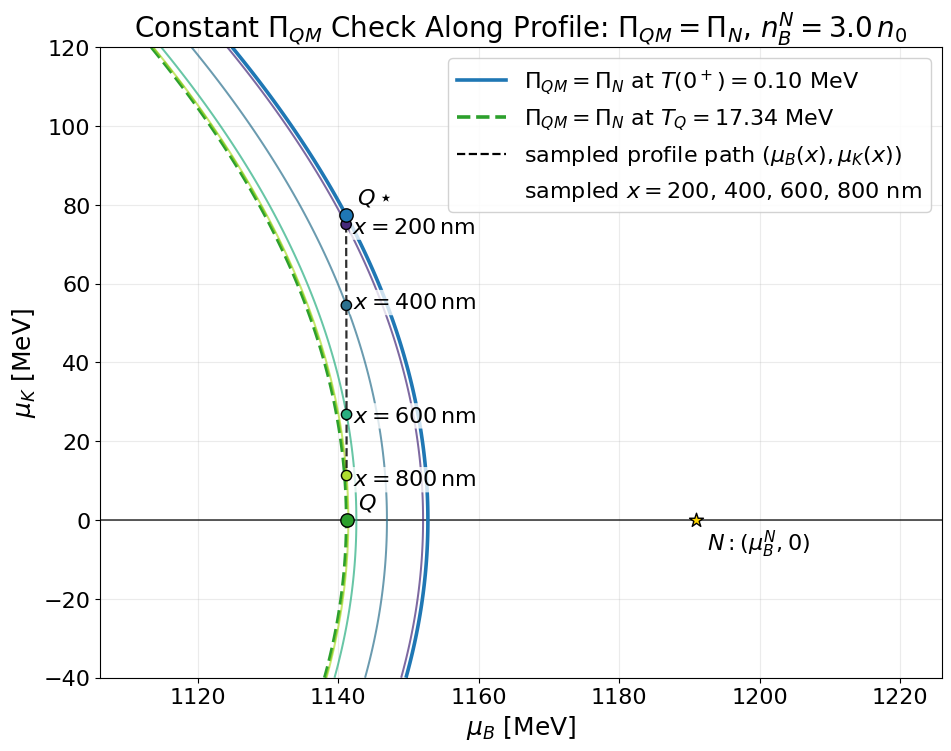

In [60]:
# VISUALIZE_ENTROPY_TQGUESS_UAGRAD_PI_QM_CONTOUR
# Check the quark-side profile against constant quark momentum-flux curves
# in the (muB, muK) plane for the u*a-gradient trial parameters.
# T = 1MeV, aQstar = 0.3, nB_N = 3n0, B^1/4 = 180

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolvePNM
from RMFsolver.phase_velocity import PQM, edensQM, nB_QM

required_pi_contour_names = [
    'res_entropy_tq_uagrad_trial',
    'T_entropy_tq_uagrad_trial',
    'nB_N_entropy_tq_uagrad_trial',
    'B14_entropy_tq_uagrad_trial',
    'ms_entropy_tq_uagrad_trial',
    'n0',
]
missing_pi_contour_names = [
    name for name in required_pi_contour_names if name not in globals()
]
if missing_pi_contour_names:
    raise RuntimeError(
        'Run the ENTROPY_TQGUESS_UAGRAD_PROFILE_TRIAL cell first. Missing names: '
        + ', '.join(missing_pi_contour_names)
    )

required_pi_contour_keys = [
    'x', 'muB', 'muK', 'T_profile',
    'jB', 'Pi', 'T_Q', 'muB_Q', 'muB_Qstar', 'muK_Qstar'
]
missing_pi_contour_keys = [
    key for key in required_pi_contour_keys if key not in res_entropy_tq_uagrad_trial
]
if missing_pi_contour_keys:
    raise RuntimeError(
        'Entropy-TQguess u*a-gradient result is missing contour inputs: '
        + ', '.join(missing_pi_contour_keys)
    )

# The conserved momentum flux Pi_N is the target for every contour.
# Each curve solves Pi_QM(muB, muK; T_slice) = Pi_N at one chosen temperature slice.
T_interface_pi_contour = float(T_entropy_tq_uagrad_trial)
T_Q_pi_contour = float(res_entropy_tq_uagrad_trial['T_Q'])
B14_pi_contour = float(B14_entropy_tq_uagrad_trial)
ms_pi_contour = float(ms_entropy_tq_uagrad_trial)
jB_pi_contour = float(res_entropy_tq_uagrad_trial['jB'])
Pi_solver_target = float(res_entropy_tq_uagrad_trial['Pi'])

muB_Q = float(res_entropy_tq_uagrad_trial['muB_Q'])
muK_Q = 0.0
muB_Qstar = float(res_entropy_tq_uagrad_trial['muB_Qstar'])
muK_Qstar = float(res_entropy_tq_uagrad_trial['muK_Qstar'])

# Put the upstream nuclear state on the same plane as a reference point.
# It is not a quark state, so it is only marked as (muB_N, 0), not tested on a quark contour.
upstream_N_sol = RMFsolvePNM(
    nB_N_entropy_tq_uagrad_trial,
    T_interface_pi_contour,
    para.paraQMCRMF3,
    sigma_init=30,
    w0_init=20,
    r03_init=-3,
    mub_init=990,
    verb=False,
)
muB_N = float(np.asarray(upstream_N_sol[0][3]).item())
muK_N = 0.0

x_prof = np.asarray(res_entropy_tq_uagrad_trial['x'], dtype=float)
muB_prof = np.asarray(res_entropy_tq_uagrad_trial['muB'], dtype=float)
muK_prof = np.asarray(res_entropy_tq_uagrad_trial['muK'], dtype=float)
T_prof = np.asarray(res_entropy_tq_uagrad_trial['T_profile'], dtype=float)

if x_prof.size < 2:
    raise RuntimeError('Need at least two profile points for the Pi_QM contour path diagnostic.')

# Sort and de-duplicate the BVP profile before interpolation.
# The profile x coordinate is converted to nm only for picking/labeling the sampled locations.
sort_idx = np.argsort(x_prof)
x_sorted = x_prof[sort_idx]
muB_sorted = muB_prof[sort_idx]
muK_sorted = muK_prof[sort_idx]
T_sorted = T_prof[sort_idx]
x_unique_all, unique_idx = np.unique(x_sorted, return_index=True)
muB_unique_all = muB_sorted[unique_idx]
muK_unique_all = muK_sorted[unique_idx]
T_unique_all = T_sorted[unique_idx]

finite_unique = (
    np.isfinite(x_unique_all)
    & np.isfinite(muB_unique_all)
    & np.isfinite(muK_unique_all)
    & np.isfinite(T_unique_all)
)
x_unique = x_unique_all[finite_unique]
muB_unique = muB_unique_all[finite_unique]
muK_unique = muK_unique_all[finite_unique]
T_unique = T_unique_all[finite_unique]

if x_unique.size < 2:
    raise RuntimeError('Need at least two finite profile points for the Pi_QM contour path diagnostic.')

x_unique_nm = x_unique * const.MeV_fm / 1.0e6

# Select fixed diagnostic locations in the active transition region.
# These are easier to read than adaptive samples and avoid crowding near the flat Q tail.
x_sample_nm_requested = np.array([200.0, 400.0, 600.0, 800.0], dtype=float)
x_sample_nm = x_sample_nm_requested[
    (x_sample_nm_requested >= float(np.nanmin(x_unique_nm)))
    & (x_sample_nm_requested <= float(np.nanmax(x_unique_nm)))
]

if x_sample_nm.size != x_sample_nm_requested.size:
    raise RuntimeError('The profile must cover all requested x samples: 200, 400, 600, 800 nm.')

n_profile_samples = x_sample_nm.size
x_sample = x_sample_nm * 1.0e6 / const.MeV_fm
muB_sample = np.interp(x_sample, x_unique, muB_unique)
muK_sample = np.interp(x_sample, x_unique, muK_unique)
T_sample = np.interp(x_sample, x_unique, T_unique)

def Pi_QM_ms(muB, muK, T_eval):
    """Quark momentum flux h*u^2 + P at fixed jB and temperature T_eval."""
    nB_val = float(nB_QM(muB, muK, B14_pi_contour, T_eval, ms=ms_pi_contour))
    if nB_val <= 0.0 or not np.isfinite(nB_val):
        return np.nan
    P_val = float(PQM(muB, muK, B14_pi_contour, T_eval, ms=ms_pi_contour))
    e_val = float(edensQM(muB, muK, B14_pi_contour, T_eval, ms=ms_pi_contour, include_em=False))
    u_val = jB_pi_contour / nB_val
    return float((P_val + e_val) * u_val * u_val + P_val)

# Build one common (muB, muK) plane that includes N, Qstar, Q, and sampled profile points.
muB_points_for_limits = np.concatenate(([muB_N, muB_Qstar, muB_Q], muB_sample))
muB_margin = max(35.0, 0.18 * (np.nanmax(muB_points_for_limits) - np.nanmin(muB_points_for_limits) + 1.0))
muB_grid = np.linspace(np.nanmin(muB_points_for_limits) - muB_margin, np.nanmax(muB_points_for_limits) + muB_margin, 130)
muK_grid = np.linspace(-40.0, 120.0, 130)
MU_B, MU_K = np.meshgrid(muB_grid, muK_grid)

def build_pi_grid(T_eval):
    grid = np.empty_like(MU_B)
    for i in range(MU_B.shape[0]):
        for j in range(MU_B.shape[1]):
            grid[i, j] = Pi_QM_ms(float(MU_B[i, j]), float(MU_K[i, j]), float(T_eval))
    return grid

# Qstar and Q get their own endpoint contours; the selected points are extra slices in between.
Pi_grid_Qstar = build_pi_grid(T_interface_pi_contour)
Pi_grid_Q = build_pi_grid(T_Q_pi_contour)
Pi_grids_sample = [build_pi_grid(T_eval) for T_eval in T_sample]

Qstar_residual = Pi_QM_ms(muB_Qstar, muK_Qstar, T_interface_pi_contour) - Pi_solver_target
Q_residual = Pi_QM_ms(muB_Q, muK_Q, T_Q_pi_contour) - Pi_solver_target
profile_residuals = np.array([
    Pi_QM_ms(muB_sample[k], muK_sample[k], T_sample[k]) - Pi_solver_target
    for k in range(n_profile_samples)
], dtype=float)
residual_norm = max(abs(Pi_solver_target), 1.0)
Qstar_residual_norm = Qstar_residual / residual_norm
Q_residual_norm = Q_residual / residual_norm
profile_residuals_norm = profile_residuals / residual_norm

TitleFont = 20
LabelFont = 18
TickFont = 16
LegendFont = 16

fig, ax = plt.subplots(figsize=(9.4, 7.4), constrained_layout=True)
curve_colors = plt.cm.viridis(np.linspace(0.12, 0.88, n_profile_samples))
Qstar_color = 'tab:blue'
Q_color = 'tab:green'

# Black reference line: muK = 0. Q and N live on this line by construction.
ax.axhline(0.0, color='k', lw=1.2, alpha=0.75)

# Endpoint contours: Qstar belongs to the interface-temperature curve, while Q belongs to T_Q.
ax.contour(
    MU_B,
    MU_K,
    Pi_grid_Qstar - Pi_solver_target,
    levels=[0.0],
    colors=[Qstar_color],
    linewidths=2.6,
)
ax.contour(
    MU_B,
    MU_K,
    Pi_grid_Q - Pi_solver_target,
    levels=[0.0],
    colors=[Q_color],
    linewidths=2.6,
    linestyles='--',
)

# Intermediate contours use temperatures sampled from the muK-relaxation part of the profile.
for k, Pi_grid_k in enumerate(Pi_grids_sample):
    ax.contour(
        MU_B,
        MU_K,
        Pi_grid_k - Pi_solver_target,
        levels=[0.0],
        colors=[curve_colors[k]],
        linewidths=1.45,
        alpha=0.70,
    )

# Dashed path through the selected reconstructed profile points in (muB, muK).
ax.plot(muB_sample, muK_sample, color='k', lw=1.6, ls='--', alpha=0.82, zorder=4)
ax.scatter(muB_sample, muK_sample, s=55, c=curve_colors, edgecolor='k', zorder=5)

# Mark the special reference points separately from the selected x samples.
ax.scatter([muB_N], [muK_N], s=110, marker='*', color='gold', edgecolor='k', zorder=6)
ax.scatter([muB_Qstar], [muK_Qstar], s=92, color=Qstar_color, edgecolor='k', zorder=6)
ax.scatter([muB_Q], [muK_Q], s=92, color=Q_color, edgecolor='k', zorder=6)
ax.annotate(r'$N:(\mu_B^N,0)$', (muB_N, muK_N), xytext=(8, -22), textcoords='offset points', fontsize=LegendFont)
ax.annotate(r'$Q\star$', (muB_Qstar, muK_Qstar), xytext=(8, 8), textcoords='offset points', fontsize=LegendFont)
ax.annotate(r'$Q$', (muB_Q, muK_Q), xytext=(8, 8), textcoords='offset points', fontsize=LegendFont)

# Text labels identify the sampled profile points, so the markers do not need legend entries.
# Place them to the left of the points with staggered vertical offsets so they do not hit each other
# or the top-right legend.
label_offsets = [(93, -2), (93, 2), (93, -1), (93, -3)]
for k in range(n_profile_samples):
    offset = label_offsets[k % len(label_offsets)]
    ax.annotate(
        rf'$x={x_sample_nm[k]:.0f}\,\mathrm{{nm}}$',
        (muB_sample[k], muK_sample[k]),
        xytext=offset,
        textcoords='offset points',
        fontsize=LegendFont,
        ha='right',
        va='center',
        bbox={'boxstyle': 'round,pad=0.12', 'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.78},
    )

# Combine the curve legend and residual summary into one top-right box.
legend_blank = Line2D([], [], color='none', lw=0)
legend_handles = [
    Line2D([0], [0], color=Qstar_color, lw=2.6, label=rf'$\Pi_{{QM}}=\Pi_N$ at $T(0^+)={T_interface_pi_contour:.2f}$ MeV'),
    #Line2D([0], [0], color='0.45', lw=1.45, label=rf'selected $T(x)$ slices at $x={x_sample_nm[0]:.0f}$, {x_sample_nm[1]:.0f}, {x_sample_nm[2]:.0f}, {x_sample_nm[3]:.0f} nm'),
    Line2D([0], [0], color=Q_color, lw=2.6, ls='--', label=rf'$\Pi_{{QM}}=\Pi_N$ at $T_Q={T_Q_pi_contour:.2f}$ MeV'),
    Line2D([0], [0], color='k', lw=1.6, ls='--', label=r'sampled profile path $(\mu_B(x),\mu_K(x))$'),
    #Line2D([0], [0], color='k', lw=1.2, label=r'$\mu_K=0$'),
    #legend_blank,
    legend_blank,
    legend_blank,
    #legend_blank,
    #legend_blank,
]
legend_labels = [
    rf'$\Pi_{{QM}}=\Pi_N$ at $T(0^+)={T_interface_pi_contour:.2f}$ MeV',
    #rf'selected $T(x)$ slices at $x={x_sample_nm[0]:.0f}$, {x_sample_nm[1]:.0f}, {x_sample_nm[2]:.0f}, {x_sample_nm[3]:.0f} nm',
    rf'$\Pi_{{QM}}=\Pi_N$ at $T_Q={T_Q_pi_contour:.2f}$ MeV',
    r'sampled profile path $(\mu_B(x),\mu_K(x))$',
    #r'$\mu_K=0$',
    #rf'$\Pi_N={Pi_solver_target:.4e}$',
    rf'sampled $x={x_sample_nm[0]:.0f}$, {x_sample_nm[1]:.0f}, {x_sample_nm[2]:.0f}, {x_sample_nm[3]:.0f} nm',
    #rf'$Q\star$ residual$/\Pi_N={Qstar_residual_norm:.2e}$',
    #rf'$Q$ residual$/\Pi_N={Q_residual_norm:.2e}$',
    #rf'max sampled residual$/\Pi_N={np.nanmax(np.abs(profile_residuals_norm)):.2e}$',
]

ax.set_xlabel(r'$\mu_B$ [MeV]', fontsize=LabelFont)
ax.set_ylabel(r'$\mu_K$ [MeV]', fontsize=LabelFont)
ax.set_ylim(-40.0, 120.0)
ax.tick_params(labelsize=TickFont)
ax.ticklabel_format(style='plain', axis='x', useOffset=False)
ax.grid(alpha=0.25)
ax.legend(
    handles=legend_handles,
    labels=legend_labels,
    fontsize=LegendFont,
    loc='upper right',
    framealpha=0.88,
    handlelength=2.2,
    handletextpad=0.8,
)

ax.set_title(
    rf'Constant $\Pi_{{QM}}$ Check Along Profile: $\Pi_{{QM}}=\Pi_N$, '
    rf'$n_{{B}}^{{N}}={nB_N_entropy_tq_uagrad_trial / n0:.1f}\,n_0$',
    fontsize=TitleFont,
)

fig.savefig(
    'entropy_tqguess_uagrad_pi_qm_contour.pdf',
    dpi=300,
    bbox_inches='tight',
)
plt.show()
